# Лабораторная работа 4. Линейные модели: метод ближайших соседей
## Учебная задача. Ирисы Фишера

In [5]:
import pandas as pd
import numpy as np

data_source = 'datasets/iris/iris.data'
d = pd.read_table(data_source, delimiter=',')
d.head()

,5.1,3.5,1.4,0.2,Iris-setosa
0,4.9,3.0,1.4,0.2,Iris-setosa
1,4.7,3.2,1.3,0.2,Iris-setosa
2,4.6,3.1,1.5,0.2,Iris-setosa
3,5.0,3.6,1.4,0.2,Iris-setosa
4,5.4,3.9,1.7,0.4,Iris-setosa


In [2]:
import pandas as pd
import numpy as np

data_source = 'datasets/iris/iris.data'
d = pd.read_table(data_source, delimiter=',', header=None)
d.head()

,0,1,2,3,4
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
import pandas as pd
import numpy as np

data_source = 'datasets/iris/iris.data'
d = pd.read_table(data_source, delimiter=',',
                  header=None,
                  names=['sepal_length','sepal_width',
                         'petal_length','petal_width','answer'])
d.head()

,sepal_length,sepal_width,petal_length,petal_width,answer
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


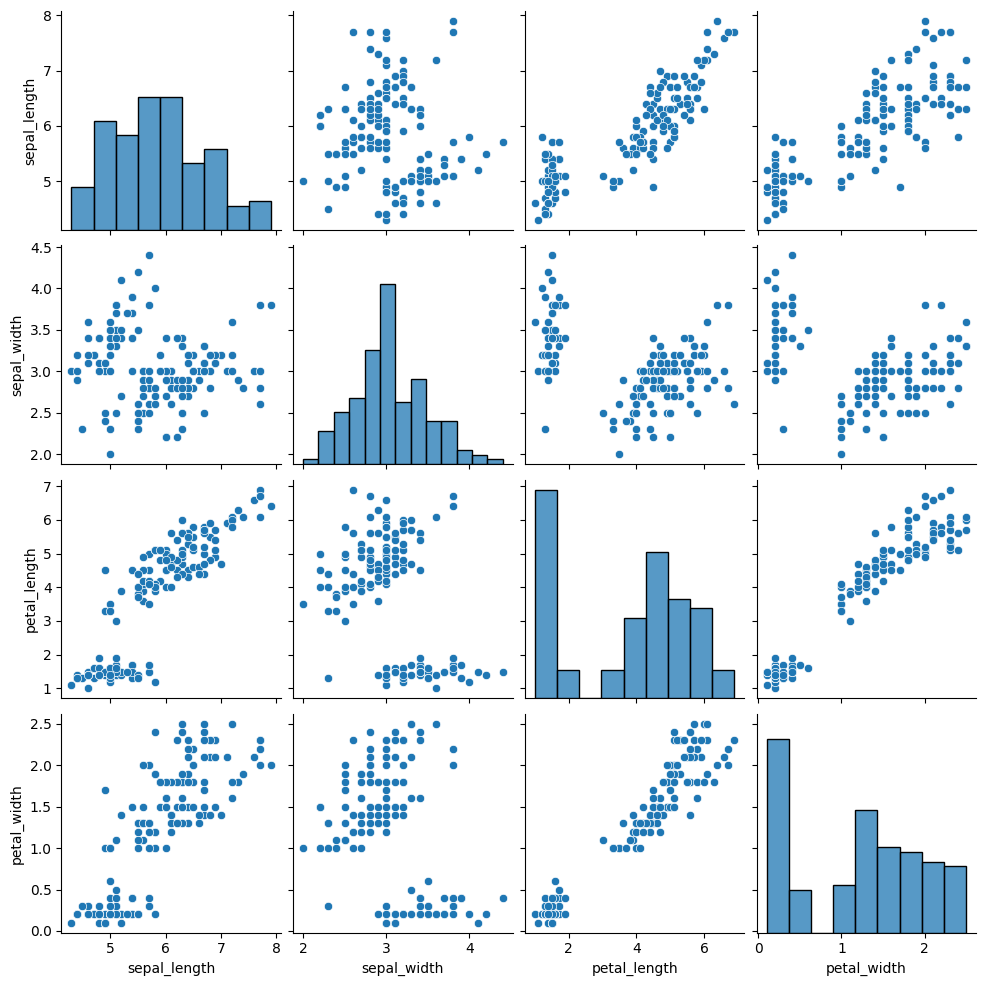

In [4]:
import seaborn as sb
%matplotlib inline
sb.pairplot(d)

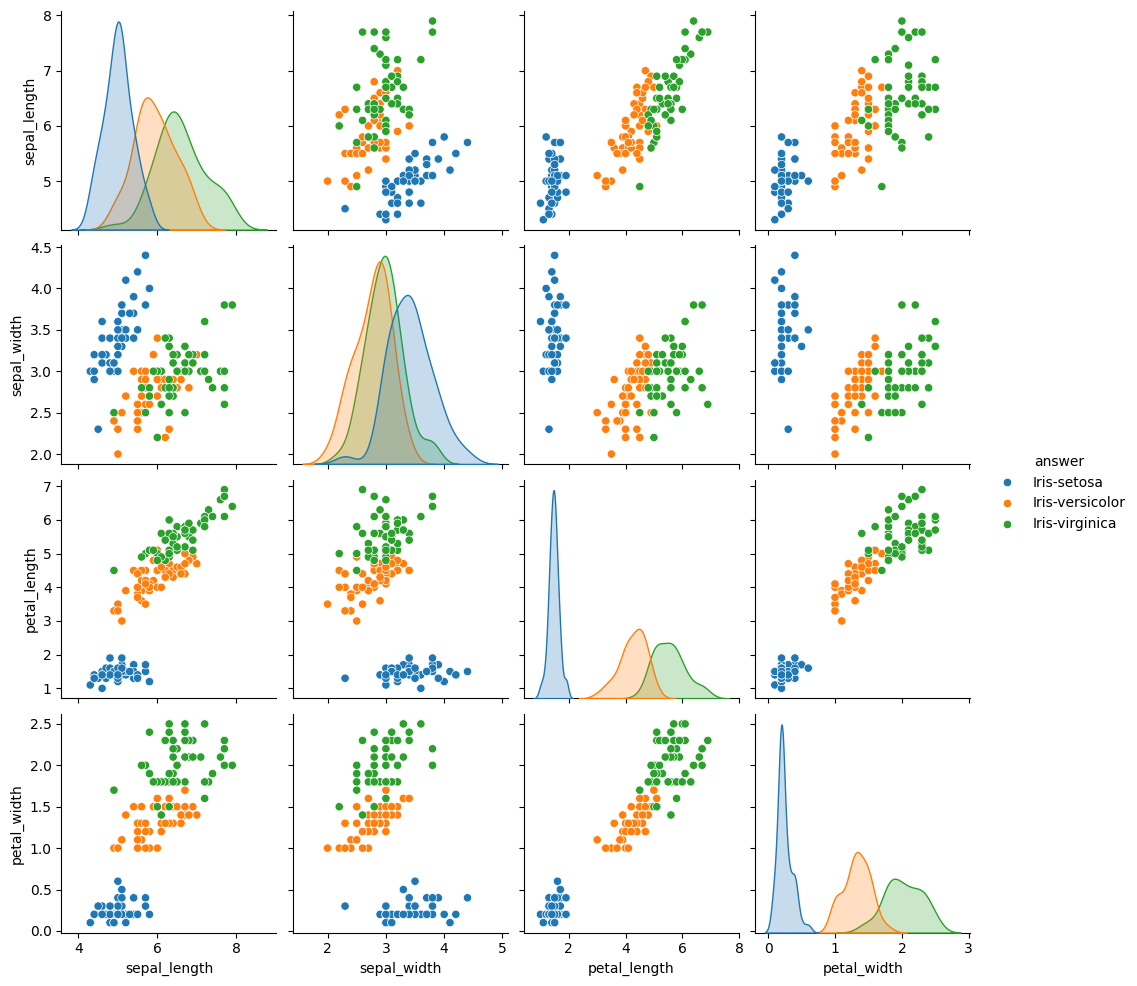

In [5]:
import seaborn as sb
%matplotlib inline
sb.pairplot(d, hue='answer')

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X_train = d[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]

y_train = d['answer']

K = 3

# Создание и настройка классификатора
knn = KNeighborsClassifier(n_neighbors=K)
# построение модели классификатора (процедура обучения)
knn.fit(X_train, y_train)

# Использование классификатора
# Объявление признаков объекта
X_test = np.array([[1.2, 1.0, 2.8, 1.2]])
# Получение ответа для нового объекта
target = knn.predict(X_test)
print(target)

['Iris-versicolor']


C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_holdout, y_train, y_holdout = \
            train_test_split(d[['sepal_length', 'sepal_width',
                                'petal_length', 'petal_width']],
                             d['answer'],
                             test_size=0.3,
                             random_state=17)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_holdout)
accur = accuracy_score(y_holdout, knn_pred)
print('accuracy: ', accur)

accuracy:  0.9777777777777777


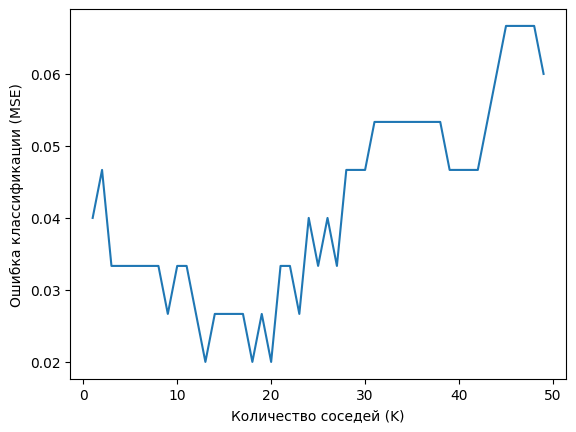

Оптимальные значения K:  [13, 18, 20]


In [9]:
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

# Значения параметра K
k_list = list(range(1,50))
# Пустой список для хранения значений точности
cv_scores = []
# В цикле проходим все значения K
for K in k_list:
    knn = KNeighborsClassifier(n_neighbors=K)
    scores = cross_val_score(knn, d.iloc[ : , 0:4 ], d['answer'], cv=10, scoring='accuracy')
    cv_scores.append(scores.mean())

# Вычисляем ошибку (misclassification error)
MSE = [1-x for x in cv_scores]

# Строим график
plt.plot(k_list, MSE)
plt.xlabel('Количество соседей (K)');
plt.ylabel('Ошибка классификации (MSE)')
plt.show()

# Ищем минимум
k_min = min(MSE)

# Пробуем найти прочие минимумы (если их несколько)
all_k_min = []
for i in range(len(MSE)):
    if MSE[i] <= k_min:
        all_k_min.append(k_list[i])

# печатаем все K, оптимальные для модели
print('Оптимальные значения K: ', all_k_min)

# Индивидуальное задание. Классификация нарушения сна

In [1]:
import pandas as pd

data_source = 'datasets/sleep_health/Sleep_health_and_lifestyle_dataset.csv'
d = pd.read_table(data_source, delimiter=',')

# Пропуски в целевом признаке означают отсутствие нарушения сна
d['Sleep Disorder'] = d['Sleep Disorder'].fillna('None')

d.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [2]:
features = ['Sleep Duration', 'Quality of Sleep',
            'Physical Activity Level', 'Stress Level', 'Heart Rate']

X = d[features]
y = d['Sleep Disorder']

print(X.shape)
print(y.value_counts())

(374, 5)
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


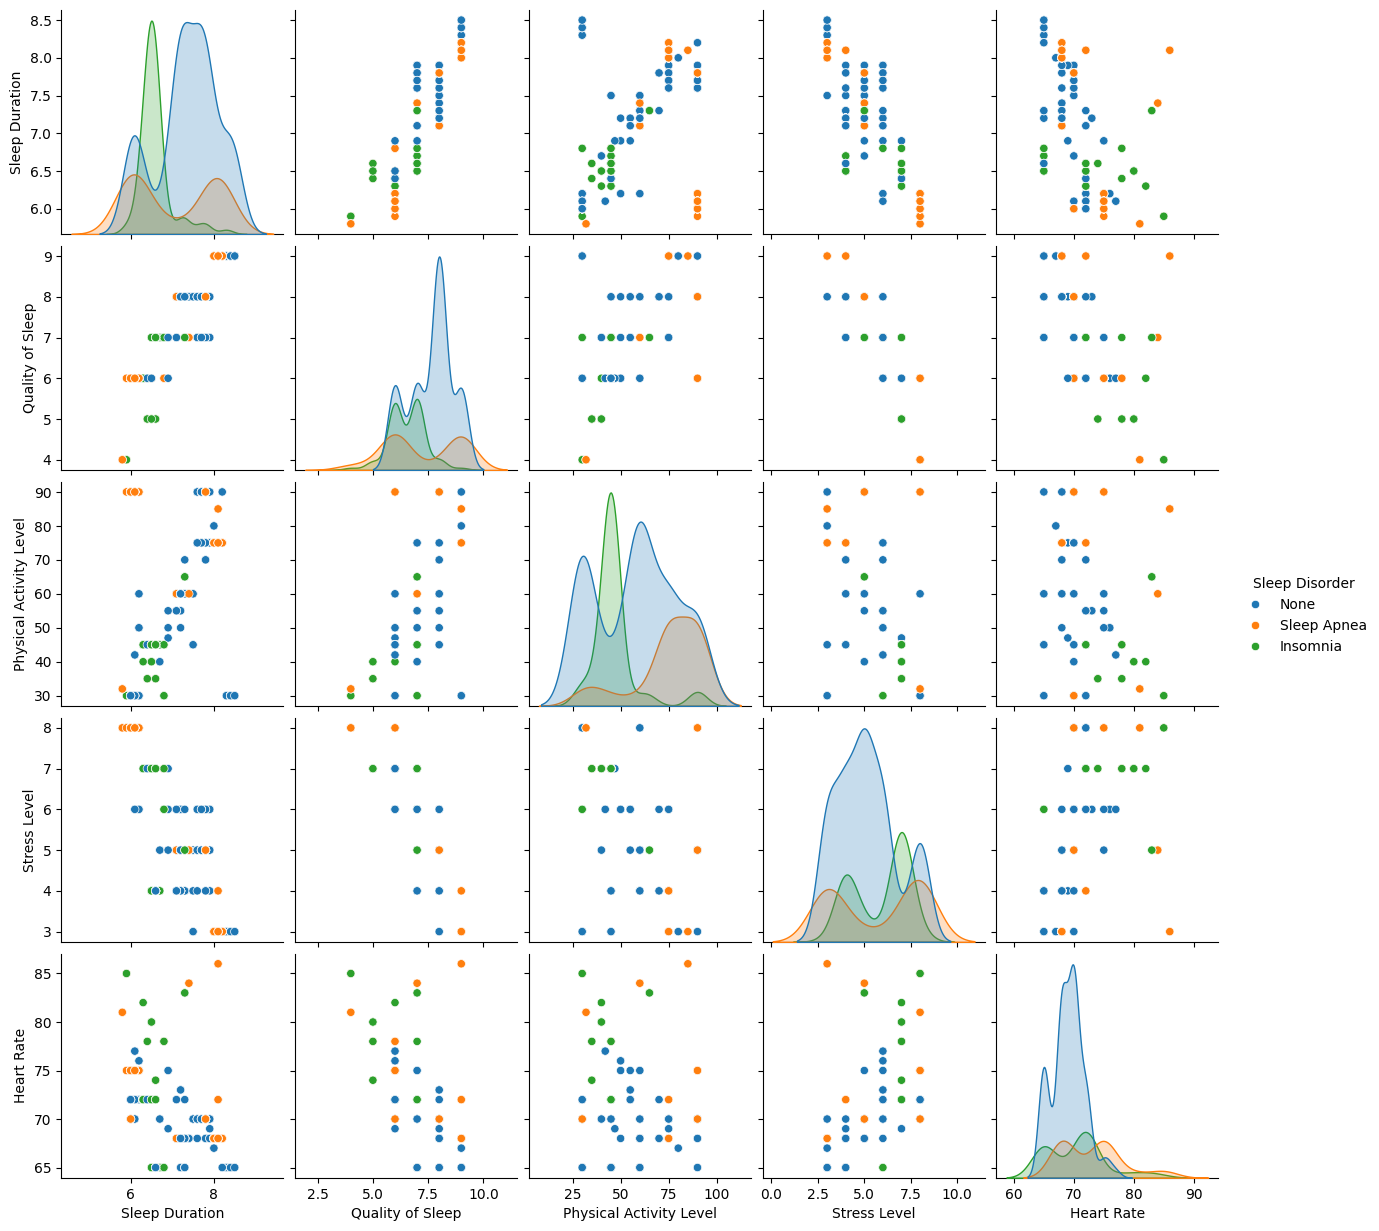

In [3]:
import seaborn as sb
%matplotlib inline
sb.pairplot(d[features + ['Sleep Disorder']], hue='Sleep Disorder')

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Классификатор с заданным пользователем значением K
K = int(input("Введите значение K: "))

knn = KNeighborsClassifier(n_neighbors=K)
knn.fit(X, y)

X_test = np.array([[7.0, 7, 60, 5, 70]])
target = knn.predict(X_test)
print(target)

Введите значение K:  5


['None']


C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [7]:
from sklearn.model_selection import train_test_split

# Оценка hold-out для различных долей тестовой подвыборки и значений K
for test_size in [0.2, 0.3, 0.4]:
    print('test_size =', test_size)
    X_train, X_holdout, y_train, y_holdout = train_test_split(
        X, y, test_size=test_size, random_state=17)
    for K in [1, 3, 5, 7, 9]:
        knn = KNeighborsClassifier(n_neighbors=K)
        knn.fit(X_train, y_train)
        knn_pred = knn.predict(X_holdout)
        accur = accuracy_score(y_holdout, knn_pred)
        print('  K =', K, 'accuracy =', round(accur, 4))

test_size = 0.2
  K = 1 accuracy = 0.8933
  K = 3 accuracy = 0.9067
  K = 5 accuracy = 0.88
  K = 7 accuracy = 0.8667
  K = 9 accuracy = 0.8533
test_size = 0.3
  K = 1 accuracy = 0.823
  K = 3 accuracy = 0.9204
  K = 5 accuracy = 0.8938
  K = 7 accuracy = 0.8673
  K = 9 accuracy = 0.8673
test_size = 0.4
  K = 1 accuracy = 0.92
  K = 3 accuracy = 0.9067
  K = 5 accuracy = 0.8867
  K = 7 accuracy = 0.8733
  K = 9 accuracy = 0.86


cv = 5 -> оптимальные значения K: [5]
cv = 10 -> оптимальные значения K: [6]


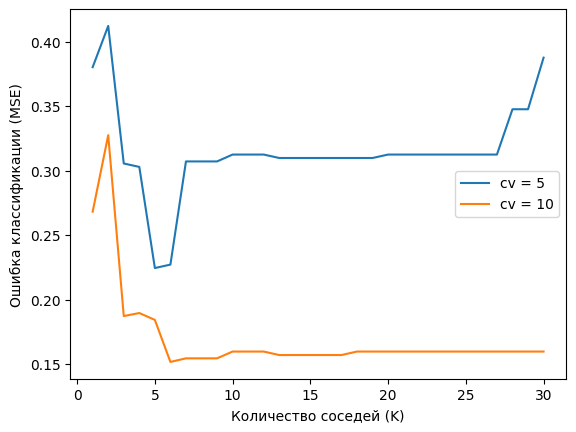

In [8]:
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

# Оценка cross validation для различных значений K и числа fold
k_list = list(range(1, 31))
for cv in [5, 10]:
    cv_scores = []
    for K in k_list:
        knn = KNeighborsClassifier(n_neighbors=K)
        scores = cross_val_score(knn, X, y, cv=cv, scoring='accuracy')
        cv_scores.append(scores.mean())

    MSE = [1-x for x in cv_scores]
    plt.plot(k_list, MSE, label='cv = %d' % cv)

    k_min = min(MSE)
    all_k_min = []
    for i in range(len(MSE)):
        if MSE[i] <= k_min:
            all_k_min.append(k_list[i])
    print('cv =', cv, '-> оптимальные значения K:', all_k_min)

plt.xlabel('Количество соседей (K)')
plt.ylabel('Ошибка классификации (MSE)')
plt.legend()
plt.show()

In [9]:
# Использование классификатора с оптимальным значением K
K = 5

knn = KNeighborsClassifier(n_neighbors=K)
knn.fit(X, y)

X_test = np.array([[6.0, 6, 40, 8, 75],
                   [7.5, 8, 75, 4, 68]])
target = knn.predict(X_test)
print(target)

['Insomnia' 'Sleep Apnea']


C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
